<a href="https://colab.research.google.com/github/Gopikaashok/Gopikaashok/blob/main/Netflix_Data_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

url = "https://raw.githubusercontent.com/shivamb/netflix-shows/master/netflix_titles.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")

HTTPError: HTTP Error 404: Not Found

In [2]:
df.head()

NameError: name 'df' is not defined

In [5]:
import pandas as pd

url = "https://raw.githubusercontent.com/shivamb/netflix-shows/master/netflix_titles.csv"

df = pd.read_csv(url)

print("Netflix dataset loaded successfully!")


HTTPError: HTTP Error 404: Not Found

In [7]:
import pandas as pd

df = pd.read_csv('/content/netflix_titles.csv')

print("Netflix dataset loaded successfully!")


Netflix dataset loaded successfully!


In [8]:
df.head()


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [9]:
df.shape


(8807, 12)

In [10]:
df.columns


Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description'],
      dtype='object')

In [11]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [12]:
df.isnull().sum()


,0
show_id,0
type,0
title,0
director,2634
cast,825
country,831
date_added,10
release_year,0
rating,4
duration,3


In [13]:
df['type'].value_counts()

,count
type,
Movie,6131
TV Show,2676


In [14]:
df['country'].value_counts().head(10)

,count
country,
United States,2818
India,972
United Kingdom,419
Japan,245
South Korea,199
Canada,181
Spain,145
France,124
Mexico,110


In [15]:
df['listed_in'].value_counts().head(10)

,count
listed_in,
"Dramas, International Movies",362
Documentaries,359
Stand-Up Comedy,334
"Comedies, Dramas, International Movies",274
"Dramas, Independent Movies, International Movies",252
Kids' TV,220
Children & Family Movies,215
"Children & Family Movies, Comedies",201
"Documentaries, International Movies",186


In [16]:
df['release_year'].value_counts().head(10)

,count
release_year,
2018,1147
2017,1032
2019,1030
2020,953
2016,902
2021,592
2015,560
2014,352
2013,288


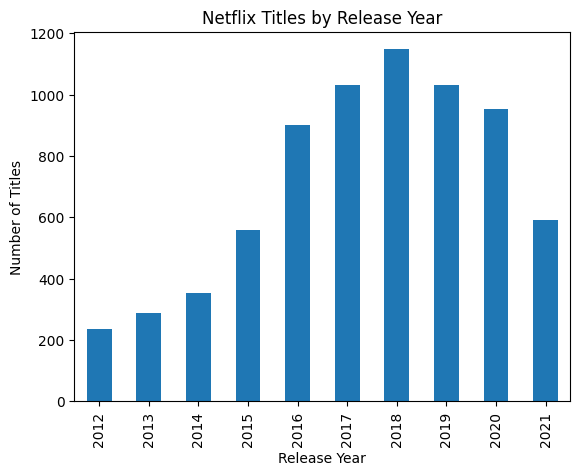

In [17]:
import matplotlib.pyplot as plt

df['release_year'].value_counts().head(10).sort_index().plot(kind='bar')

plt.title('Netflix Titles by Release Year')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')
plt.show()

In [18]:
movies = df[df['type'] == 'Movie']

movies['duration'].head(10)

,duration
0,90 min
6,91 min
7,125 min
9,104 min
12,127 min
13,91 min
16,67 min
18,94 min
22,161 min
23,61 min


In [19]:
movies['duration_minutes'] = movies['duration'].str.replace(' min', '').astype(float)

movies['duration_minutes'].mean()

/tmp/ipykernel_11804/1378630998.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  movies['duration_minutes'] = movies['duration'].str.replace(' min', '').astype(float)


np.float64(99.57718668407311)

In [20]:
movies.loc[movies['duration_minutes'].idxmax(), ['title', 'duration']]

,4253
title,Black Mirror: Bandersnatch
duration,312 min


In [21]:
movies.loc[movies['duration_minutes'].idxmin(), ['title', 'duration']]

,3777
title,Silent
duration,3 min


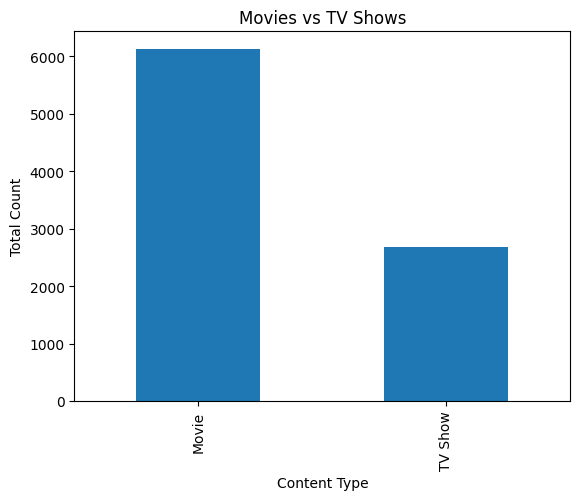

In [22]:
df['type'].value_counts().plot(kind='bar')

plt.title('Movies vs TV Shows')
plt.xlabel('Content Type')
plt.ylabel('Total Count')
plt.show()

In [23]:
df['date_added'] = pd.to_datetime(df['date_added'].str.strip())

df['year_added'] = df['date_added'].dt.year

df['year_added'].value_counts().sort_index()

,count
year_added,
2008.0,2
2009.0,2
2010.0,1
2011.0,13
2012.0,3
2013.0,11
2014.0,24
2015.0,82
2016.0,429


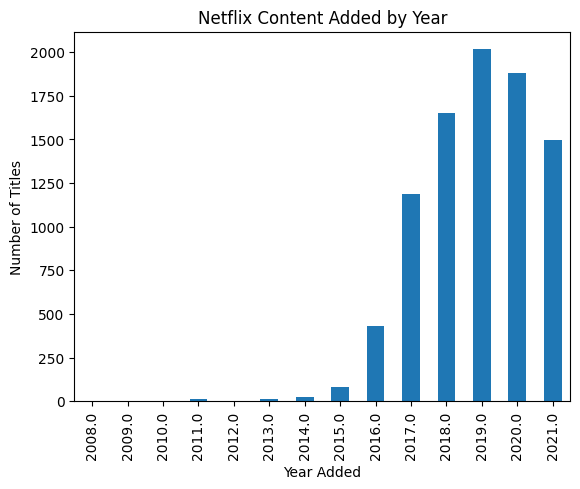

In [24]:
df['year_added'].value_counts().sort_index().plot(kind='bar')

plt.title('Netflix Content Added by Year')
plt.xlabel('Year Added')
plt.ylabel('Number of Titles')
plt.show()

In [25]:
df['rating'].value_counts().head(10)

,count
rating,
TV-MA,3207
TV-14,2160
TV-PG,863
R,799
PG-13,490
TV-Y7,334
TV-Y,307
PG,287
TV-G,220


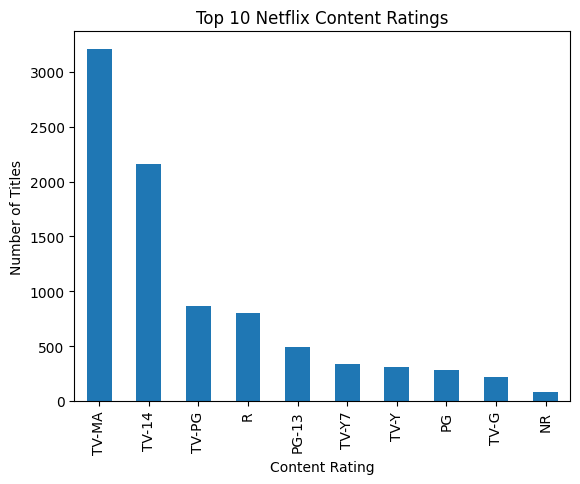

In [26]:
df['rating'].value_counts().head(10).plot(kind='bar')

plt.title('Top 10 Netflix Content Ratings')
plt.xlabel('Content Rating')
plt.ylabel('Number of Titles')
plt.show()

In [27]:
tv_shows = df[df['type'] == 'TV Show']

tv_shows['duration'].value_counts().head(10)

,count
duration,
1 Season,1793
2 Seasons,425
3 Seasons,199
4 Seasons,95
5 Seasons,65
6 Seasons,33
7 Seasons,23
8 Seasons,17
9 Seasons,9


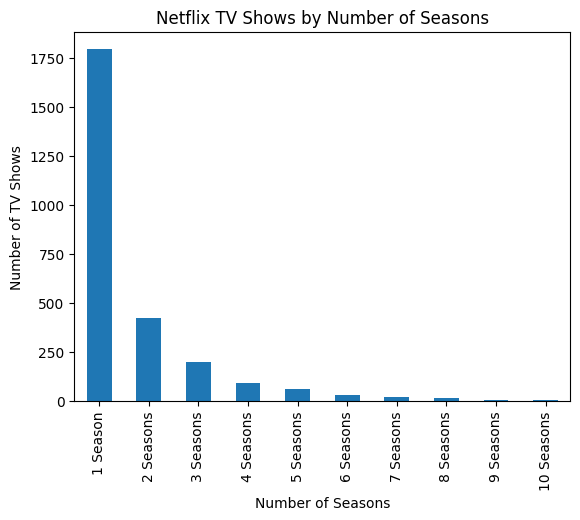

In [28]:
tv_shows['duration'].value_counts().head(10).plot(kind='bar')

plt.title('Netflix TV Shows by Number of Seasons')
plt.xlabel('Number of Seasons')
plt.ylabel('Number of TV Shows')
plt.show()